# 01 · Fundamentos de GIS para agricultura

**AgroGeo Analytics · Projeto 01** — cafeicultura em Piraju/SP

> ⚠️ Os **talhões** usados aqui são **sintéticos** (gerados por `agrogeo.synthetic`, semente fixa) e ficam dentro do limite **real** do município de Piraju (IBGE, código 3538808). Não representam nenhuma propriedade real. Substitua por seu GeoJSON real em `data/sample/` para uso prático.

## Objetivos
1. Entender **CRS/EPSG** e por que área nunca se calcula em graus.
2. Inspecionar e validar **geometrias** (polígonos, validade, vazios).
3. **Reprojetar** e comparar áreas em CRS diferentes (e ver a distorção do Web Mercator).
4. Usar **buffers** (inclusive negativos) e **interseções** — conceitos que voltam em todo o projeto.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"

## 1. CRS e EPSG

Um **CRS** (sistema de referência de coordenadas) define como números `(x, y)` correspondem a lugares da Terra. O **código EPSG** é um identificador padronizado:

| EPSG | Nome | Unidade | Uso |
|---|---|---|---|
| 4326 | WGS 84 | graus | GPS, GeoJSON, web, Earth Engine |
| 4674 | SIRGAS 2000 | graus | datum oficial no Brasil (IBGE) |
| 31982 | SIRGAS 2000 / UTM 22S | metros | medir área/distância em Piraju (lon ≈ −49,4°) |

Graus **não** são uma unidade de comprimento constante: 1° de longitude vale ~102 km em Piraju (cos 23°) e ~111 km no equador.

In [2]:
municipio = gpd.read_file(DATA_SAMPLE / "municipio_3538808.geojson")
talhoes = gpd.read_file(DATA_SAMPLE / "talhoes_sinteticos.geojson")
print("Município:", municipio.loc[0, "nome"], "| CRS:", municipio.crs)
print("Bounds (lon/lat):", municipio.total_bounds.round(4))
print("Talhões:", len(talhoes), "| CRS:", talhoes.crs, "| todos sintéticos:", bool(talhoes["SINTETICO"].all()))
talhoes.drop(columns="geometry").head()

Município: Piraju | CRS: EPSG:4326
Bounds (lon/lat): [-49.5734 -23.3367 -49.1981 -23.0515]
Talhões: 12 | CRS: EPSG:4326 | todos sintéticos: True


,talhao_id,nome,cultivar,ano_plantio,SINTETICO
0,T01,Talhão sintético 01,Catuaí Vermelho,2014,True
1,T02,Talhão sintético 02,Mundo Novo,2019,True
2,T03,Talhão sintético 03,Arara,2009,True
3,T04,Talhão sintético 04,Catuaí Amarelo,2014,True
4,T05,Talhão sintético 05,Catuaí Vermelho,2013,True


## 2. Geometria: tipos e validade

Talhões são `Polygon`. Geometrias podem estar **inválidas** (auto-interseção, "gravata-borboleta") — o que quebra interseções e áreas. Sempre valide ao importar dados de campo (KML/GeoJSON desenhados à mão).

In [3]:
print(talhoes.geom_type.value_counts().to_dict())
print("Inválidas:", int((~talhoes.geometry.is_valid).sum()), "| Vazias:", int(talhoes.geometry.is_empty.sum()))

# Exemplo didático: uma "gravata-borboleta" é inválida e pode ser reparada
from shapely.geometry import Polygon
bow = gpd.GeoDataFrame({"id": ["bowtie"]}, geometry=[Polygon([(0, 0), (1, 1), (1, 0), (0, 1)])], crs=CRS_UTM22S)
print("Antes:", bow.geometry.is_valid.iloc[0], "| Depois do reparo:", gis.validate_geometries(bow).geometry.is_valid.iloc[0])

{'Polygon': 12}
Inválidas: 0 | Vazias: 0
Antes: False | Depois do reparo: True


## 3. Área: graus × metros

Calcular `.area` em EPSG:4326 devolve **graus²** — um número sem significado agrícola. O caminho correto: projetar para um CRS métrico e dividir por 10 000 (m² → ha).

In [4]:
tal = talhoes.copy()
tal["area_graus2"] = talhoes.geometry.area            # ERRADO para ha (apenas demonstração)
tal["area_ha"] = gis.area_ha(talhoes, CRS_UTM22S)      # CORRETO
tal["perimetro_m"] = gis.perimeter_m(talhoes, CRS_UTM22S)
tal["compacidade"] = gis.compactness(talhoes, CRS_UTM22S)
tal[["talhao_id", "area_graus2", "area_ha", "perimetro_m", "compacidade"]].round(6).head()

,talhao_id,area_graus2,area_ha,perimetro_m,compacidade
0,T01,0.000007,8.296366,1162.038519,0.772070
1,T02,0.000008,9.611553,1241.774550,0.783282
2,T03,0.000009,9.697221,1254.021826,0.774902
3,T04,0.000006,6.852367,1056.500313,0.771456
4,T05,0.000010,10.932272,1326.144516,0.781157


Área total dos talhões sintéticos: 98.1 ha | média 8.2 ha


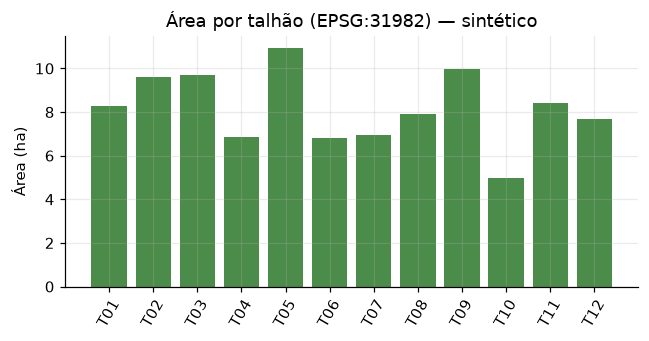

In [5]:
print(f"Área total dos talhões sintéticos: {tal['area_ha'].sum():.1f} ha | média {tal['area_ha'].mean():.1f} ha")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(tal["talhao_id"], tal["area_ha"], color="#4c8c4a")
ax.set(ylabel="Área (ha)", title="Área por talhão (EPSG:31982) — " + "sintético")
plt.xticks(rotation=60); plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "01_area_talhoes.png"); plt.show()

**Como ler o gráfico:** cada barra é a área de um talhão calculada em metros. Talhões entre ~5 e ~12 ha são plausíveis em cafeicultura, mas aqui os tamanhos vêm do gerador sintético.

## 4. Reprojeção e distorção de área

A mesma geometria em CRS diferentes deve ter áreas próximas **se o CRS preserva área** (ou é local). Compare:
- **EPSG:31982** (UTM 22S, local) — referência;
- **EPSG:5880** (SIRGAS 2000 / Brazil Polyconic) — projeção nacional;
- **EPSG:3857** (Web Mercator) — usada em mapas web; **infla áreas** longe do equador (fator ≈ 1/cos²φ).

In [6]:
cmp = pd.DataFrame({crs: talhoes.to_crs(crs).area / 1e4 for crs in ["EPSG:31982", "EPSG:5880", "EPSG:3857"]})
cmp["erro_%_5880"] = 100 * (cmp["EPSG:5880"] / cmp["EPSG:31982"] - 1)
cmp["erro_%_3857"] = 100 * (cmp["EPSG:3857"] / cmp["EPSG:31982"] - 1)
lat = np.deg2rad(abs(municipio.to_crs(4326).union_all().centroid.y))
print(f"Fator teórico do Web Mercator em Piraju (1/cos²φ): {100*(1/np.cos(lat)**2 - 1):.1f}%")
cmp[["erro_%_5880", "erro_%_3857"]].describe().loc[["mean", "min", "max"]].round(2)

Fator teórico do Web Mercator em Piraju (1/cos²φ): 18.3%


,erro_%_5880,erro_%_3857
mean,0.29,18.92
min,0.29,18.91
max,0.29,18.93


**Interpretação:** o erro do Web Mercator é grande e sistemático (~+19% em Piraju) — nunca use EPSG:3857 para medir área. O Polyconic fica muito próximo do UTM local (diferenças de décimos de %).

## 5. Buffers (inclusive negativos)

`buffer(d)` cria uma faixa de `d` metros ao redor da geometria. **Sempre em CRS métrico** — `agrogeo.gis.buffer_m` projeta, aplica e devolve ao CRS original.

Uso em agricultura:
- **buffer negativo** (ex.: −10 m) remove a borda do talhão → reduz **mistura de pixels** (um pixel Sentinel-2 de 10 m na borda mistura café com estrada/mata);
- **buffer positivo** cria faixas de entorno (ex.: proximidade de matas ou cursos d'água — respeitando a legislação aplicável).

  talhao_id  area_ha  area_interior_ha  perda_%
0       T01     8.30              7.17    13.52
1       T02     9.61              8.41    12.50
2       T03     9.70              8.48    12.52
3       T04     6.85              5.84    14.83
4       T05    10.93              9.65    11.76
Perda média de área ao excluir 10 m de borda: 13.8%


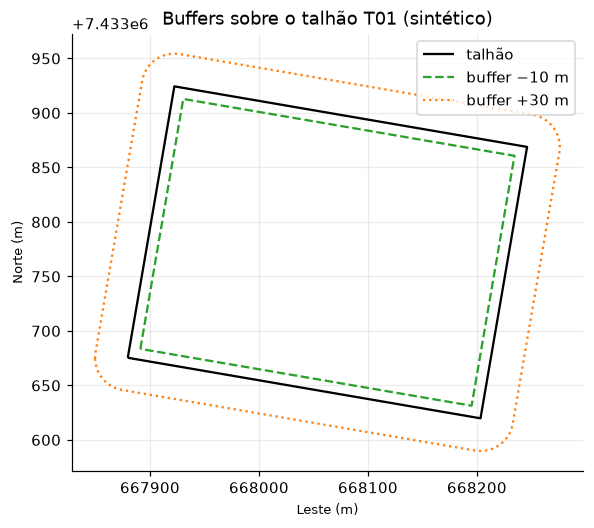

In [7]:
interior = gis.buffer_m(talhoes, -10, CRS_UTM22S)
borda_ext = gis.buffer_m(talhoes, 30, CRS_UTM22S)
res = pd.DataFrame({
    "talhao_id": talhoes["talhao_id"],
    "area_ha": gis.area_ha(talhoes, CRS_UTM22S).values,
    "area_interior_ha": gis.area_ha(interior, CRS_UTM22S).values,
})
res["perda_%"] = 100 * (1 - res["area_interior_ha"] / res["area_ha"])
print(res.round(2).head())
print(f"Perda média de área ao excluir 10 m de borda: {res['perda_%'].mean():.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
t0 = talhoes.iloc[[0]]
t0.to_crs(CRS_UTM22S).boundary.plot(ax=ax, color="k", label="talhão")
interior.iloc[[0]].to_crs(CRS_UTM22S).boundary.plot(ax=ax, color="tab:green", ls="--", label="buffer −10 m")
borda_ext.iloc[[0]].to_crs(CRS_UTM22S).boundary.plot(ax=ax, color="tab:orange", ls=":", label="buffer +30 m")
ax.set(title="Buffers sobre o talhão T01 (sintético)", xlabel="Leste (m)", ylabel="Norte (m)"); ax.legend(); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "01_buffers.png"); plt.show()

**Como ler o gráfico:** linha contínua = limite do talhão; tracejada verde = onde ficam pixels "puros" (a ≥ 10 m da borda); pontilhada laranja = entorno de 30 m.

> A perda de área (coluna `perda_%`) mostra o custo de ser conservador: em talhões pequenos, o buffer −10 m remove uma fração grande da área.

## 6. Interseções e junções espaciais

- `intersection_fraction`: que fração do talhão está dentro de um polígono (município, APP, área de manejo)?
- `overlay`: recorta camadas e devolve as peças (com área recalculada).
- `sjoin`: associa atributos pela relação espacial.

In [8]:
frac = gis.intersection_fraction(talhoes, municipio, CRS_UTM22S)
print("Fração dentro de Piraju — mín/máx:", frac.min().round(4), frac.max().round(4))

# Exemplo: um 'talhão' que ultrapassa o limite municipal (teste do conceito)
from shapely.geometry import box
borda = municipio.to_crs(CRS_UTM22S).boundary.union_all().representative_point()
teste = gpd.GeoDataFrame({"talhao_id": ["TESTE"]}, geometry=[box(borda.x - 200, borda.y - 200, borda.x + 200, borda.y + 200)], crs=CRS_UTM22S)
print("Fração do polígono de teste dentro do município:", gis.intersection_fraction(teste, municipio, CRS_UTM22S).round(3).tolist())

pecas = gis.overlay_area_ha(teste, municipio[["nome", "geometry"]], CRS_UTM22S)
print(pecas[["talhao_id", "nome", "area_ha"]].round(2))

Fração dentro de Piraju — mín/máx: 1.0 1.0
Fração do polígono de teste dentro do município: [0.651]
  talhao_id    nome  area_ha
0     TESTE  Piraju    10.41


  talhao_id municipio
0       T01    Piraju


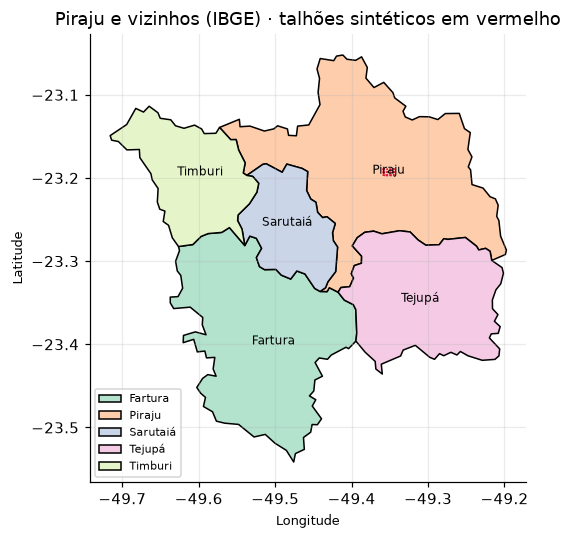

In [9]:
regiao = gpd.read_file(DATA_SAMPLE / "municipios_regiao_piraju.geojson")
# sjoin: em qual município cai o centróide de cada talhão?
cent = talhoes.to_crs(CRS_UTM22S).copy(); cent["geometry"] = cent.centroid
join = gpd.sjoin(cent.to_crs(4326), regiao[["nome", "geometry"]].rename(columns={"nome": "municipio"}), how="left", predicate="within")
print(join[["talhao_id", "municipio"]].drop_duplicates("municipio"))

fig, ax = plt.subplots(figsize=(6.5, 5))
regiao.plot(ax=ax, column="nome", cmap="Pastel2", edgecolor="k", legend=True, legend_kwds={"loc": "lower left", "fontsize": 7})
talhoes.plot(ax=ax, color="crimson")
for _, r in regiao.iterrows():
    p = r.geometry.representative_point(); ax.annotate(r["nome"], (p.x, p.y), ha="center", fontsize=8)
ax.set(title="Piraju e vizinhos (IBGE) · talhões sintéticos em vermelho", xlabel="Longitude", ylabel="Latitude"); ax.set_aspect(1 / np.cos(np.deg2rad(23.2)))
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "01_regiao.png"); plt.show()

**Como ler o mapa:** polígonos coloridos são municípios (malha IBGE, qualidade intermediária); os pontos vermelhos agrupados são os talhões sintéticos — pequenos em relação ao município, por isso aparecem como uma mancha.